# Clustering and Dimensionality Reduction | 4DT910

Samuel Fredric Berg (sb224sc)

## AI Usage

AI has been used to make sure of text uniformity, improve graph labels and tried to improve cell time efficiency.

## Imports & Config

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from IPython.display import display
from joblib import Parallel, delayed
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.preprocessing import LabelEncoder, StandardScaler
from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

SEED = 42
N_MAX = 4000

e:\4dt910\a2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Loading & Summary

In [2]:
DATASETS = {
    "MAGIC Gamma Telescope": dict(uci_id=159, target=None),
    "Dry Bean":              dict(uci_id=602, target=None),
    "Cardiotocography":      dict(uci_id=193, target="NSP"),
}

def load_clean(uci_id, target=None):
    ds = fetch_ucirepo(id=uci_id)
    X = ds.data.features.copy()
    y = ds.data.targets.copy()
    y = y.iloc[:, 0] if target is None else y[target]
    n0 = len(X)
    X = X.select_dtypes(include=[np.number])
    ok = X.notna().all(axis=1) & y.notna()
    X, y = X[ok], y[ok]
    dup = X.duplicated()
    X, y = X[~dup], y[~dup]
    X = X.loc[:, X.nunique() > 1]
    info = dict(raw_rows=n0, dropped_missing=int((~ok).sum()), dropped_duplicates=int(dup.sum()))
    return X.reset_index(drop=True), y.reset_index(drop=True), info

data = {}
desc_rows = []
for name, cfg in DATASETS.items():
    X, y, info = load_clean(cfg["uci_id"], cfg["target"])
    le = LabelEncoder()
    y_int = le.fit_transform(y.astype(str))
    classes = [str(c) for c in le.classes_]
    n_clean = len(X)
    if n_clean > N_MAX:
        X, _, y_int, _ = train_test_split(X, y_int, train_size=N_MAX, stratify=y_int, random_state=SEED)
    feat_names = list(X.columns)
    Xs = StandardScaler().fit_transform(X.values)
    data[name] = dict(X=Xs, y=np.asarray(y_int), classes=classes, features=feat_names)
    props = pd.Series(np.asarray(y_int)).value_counts(normalize=True).sort_index()
    desc_rows.append({
        "dataset": name,
        "rows (raw)": info["raw_rows"],
        "dropped (missing / dup)": f'{info["dropped_missing"]} / {info["dropped_duplicates"]}',
        "rows used": len(Xs),
        "features": Xs.shape[1],
        "classes": len(classes),
        "class proportions": ", ".join(f"{classes[i]}: {p:.0%}" for i, p in props.items()),
    })

display(pd.DataFrame(desc_rows).set_index("dataset"))

,rows (raw),dropped (missing / dup),rows used,features,classes,class proportions
dataset,,,,,,
MAGIC Gamma Telescope,19020,0 / 115,4000,10,2,"g: 65%, h: 35%"
Dry Bean,13611,0 / 68,4000,16,7,"BARBUNYA: 10%, BOMBAY: 4%, CALI: 12%, DERMASON..."
Cardiotocography,2126,0 / 15,2111,21,3,"1: 78%, 2: 14%, 3: 8%"


### Data Description & Preprocessing

Three UCI datasets are used. MAGIC Gamma Telescope has 10 image features that separate gamma signal from hadron background (2 classes, heavy overlap). Dry Bean has 16 shape features of seven bean varieties. Cardiotocography has 21 fetal heart-rate and uterine-contraction features, and the class is the fetal state `NSP` (1 normal, 2 suspect, 3 pathologic; 78% normal). Only numeric features are kept, missing values, exact duplicate rows and constant columns are dropped, labels are integer-encoded, MAGIC and Dry Bean are stratified-subsampled to 4000 rows for speed, and all features are standardised because PCA, t-SNE, K-Means, DBSCAN and Ward use Euclidean distance.

In [3]:
def scatter_labels(ax, Z, labels, title, class_names=None, s=5, legend=False, noise_gray=True):
    uniq = [u for u in np.unique(labels) if u != -1]
    pal = sns.color_palette("tab10" if len(uniq) <= 10 else "tab20", max(len(uniq), 1))
    if noise_gray and (labels == -1).any():
        m = labels == -1
        ax.scatter(Z[m, 0], Z[m, 1], s=s, color="lightgray", alpha=0.6, label="noise")
    for i, c in enumerate(uniq):
        m = labels == c
        lab = class_names[c] if class_names is not None else str(c)
        ax.scatter(Z[m, 0], Z[m, 1], s=s, color=pal[i], alpha=0.7, label=lab)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    if legend:
        ax.legend(markerscale=3, fontsize=7, loc="best", frameon=True)

## Dimensionality reduction

PCA, t-SNE and UMAP reduce each dataset to two dimensions. Quality is measured in the original standardised space against the 2D result (k = 15) with trustworthiness (are 2D neighbours true neighbours), continuity (are true neighbours kept) and the 5-fold CV 15-NN accuracy and silhouette of the true classes in 2D.

In [4]:
K_NEIGH = 15

def run_pca(X):
    return PCA(n_components=2, random_state=SEED).fit_transform(X)

def run_tsne(X, perplexity=30):
    return TSNE(n_components=2, perplexity=perplexity, init="pca",
                learning_rate="auto", random_state=SEED).fit_transform(X)

def run_umap(X, n_neighbors=15, min_dist=0.1):
    return umap.UMAP(n_components=2, n_neighbors=n_neighbors, min_dist=min_dist,
                     random_state=SEED).fit_transform(X)

def dr_metrics(X, Z, y, k=K_NEIGH):
    return dict(
        trustworthiness=trustworthiness(X, Z, n_neighbors=k),
        continuity=trustworthiness(Z, X, n_neighbors=k),
        knn_acc_2d=cross_val_score(KNeighborsClassifier(n_neighbors=k), Z, y, cv=5).mean(),
        silhouette_2d=silhouette_score(Z, y),
    )

emb = {}
dr_rows = []
for name, d in data.items():
    X, y = d["X"], d["y"]
    emb[name] = {"PCA": run_pca(X), "t-SNE": run_tsne(X, 30), "UMAP": run_umap(X, 15, 0.1)}
    for method, Z in emb[name].items():
        dr_rows.append(dict(dataset=name, method=method, **dr_metrics(X, Z, y)))

dr_df = pd.DataFrame(dr_rows)

done: MAGIC Gamma Telescope
done: Dry Bean
done: Cardiotocography


### Visual comparison

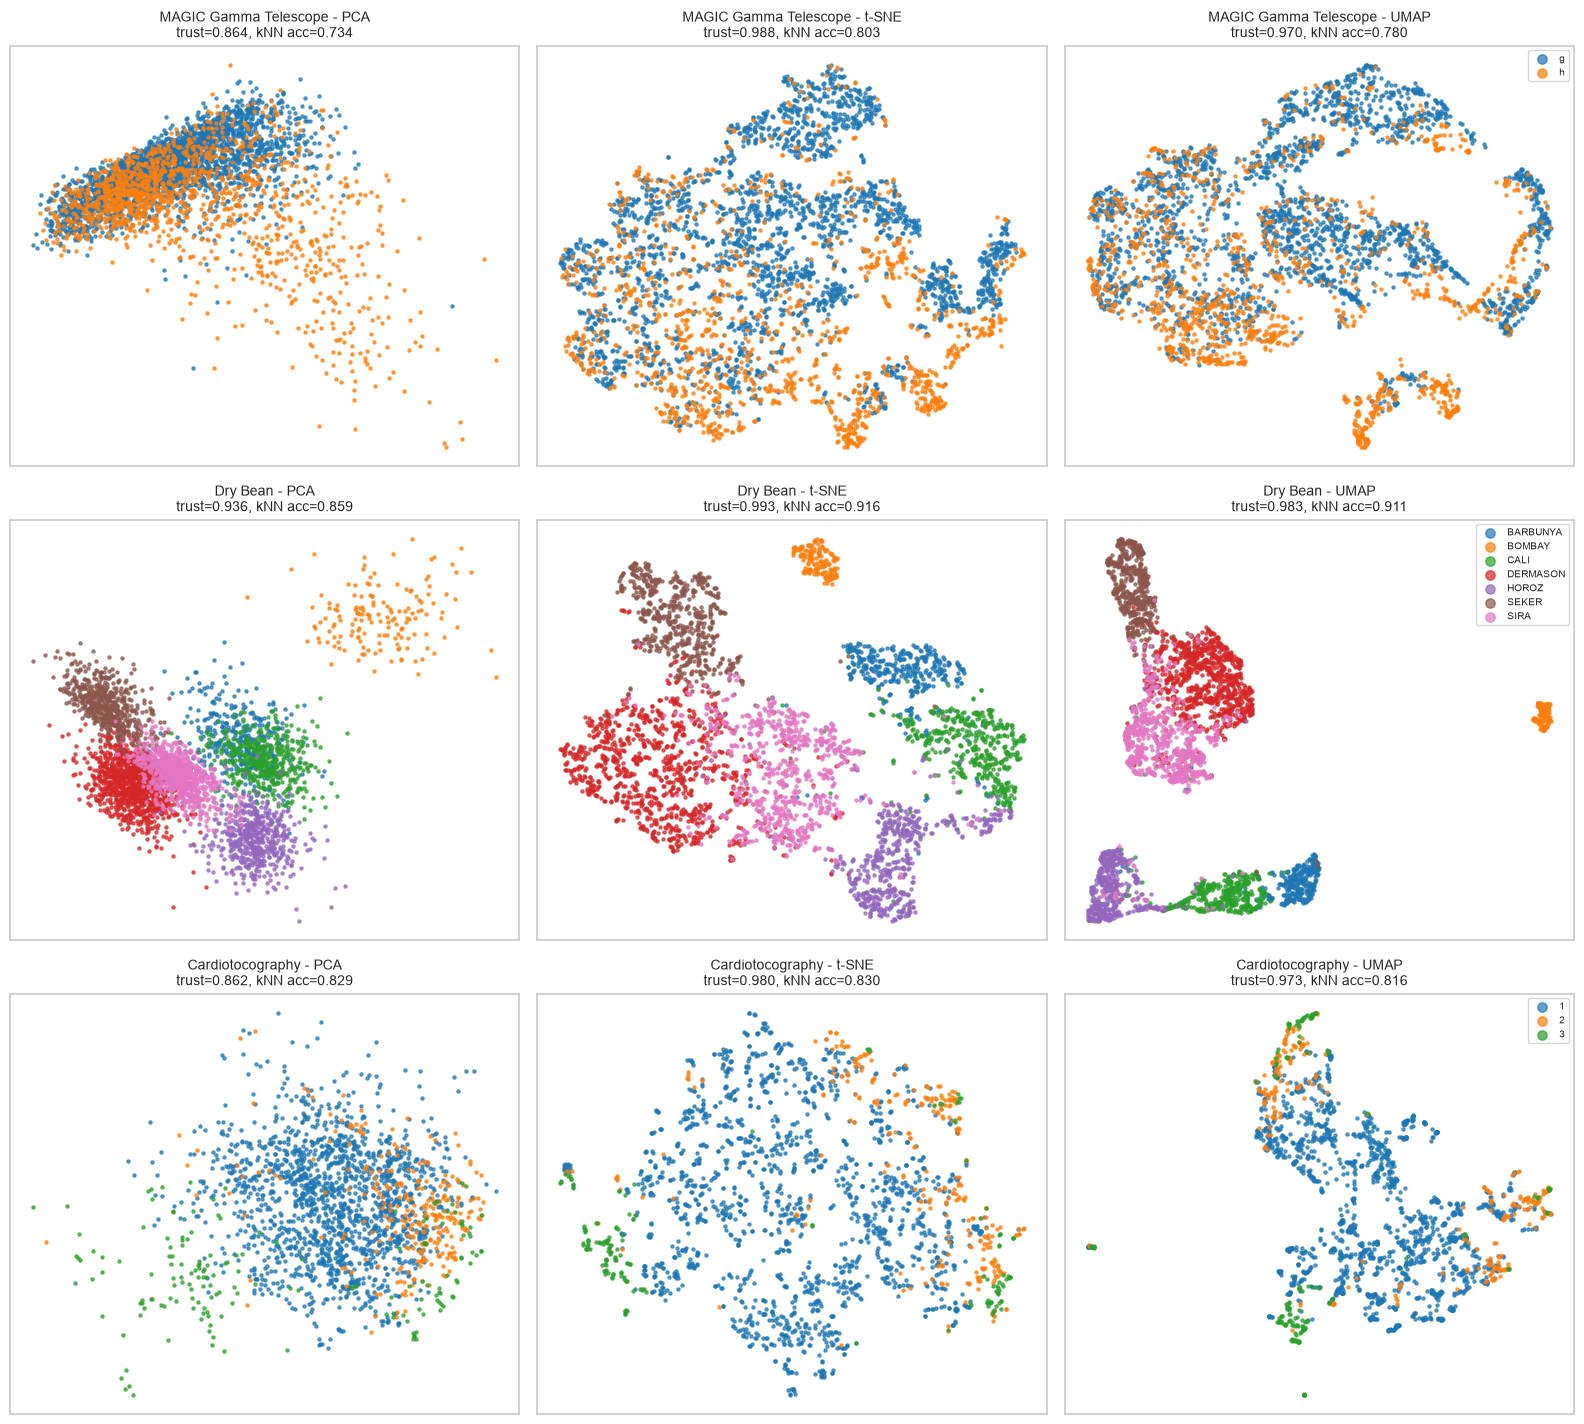

In [5]:
methods = ["PCA", "t-SNE", "UMAP"]
fig, axes = plt.subplots(len(data), 3, figsize=(16, 4.8 * len(data)))
for r, (name, d) in enumerate(data.items()):
    for c, m in enumerate(methods):
        row = dr_df[(dr_df.dataset == name) & (dr_df.method == m)].iloc[0]
        scatter_labels(axes[r, c], emb[name][m], d["y"],
                       f"{name} - {m}\ntrust={row.trustworthiness:.3f}, kNN acc={row.knn_acc_2d:.3f}",
                       d["classes"], legend=(c == 2))
plt.tight_layout()
plt.show()

### Quantitative comparison

In [6]:
display(dr_df.set_index(["dataset", "method"]).round(3))

trustworthiness  continuity  knn_acc_2d  silhouette_2d
dataset               method                                                        
MAGIC Gamma Telescope PCA               0.864       0.969       0.734          0.111
                      t-SNE             0.988       0.964       0.803          0.080
                      UMAP              0.970       0.971       0.780          0.061
Dry Bean              PCA               0.936       0.986       0.859          0.330
                      t-SNE             0.993       0.982       0.916          0.392
                      UMAP              0.983       0.983       0.912          0.449
Cardiotocography      PCA               0.862       0.960       0.829          0.100
                      t-SNE             0.980       0.963       0.830          0.095
                      UMAP              0.973       0.959       0.816          0.153

### Parameter study: t-SNE and UMAP

t-SNE `perplexity` (5, 30, 100) and UMAP `n_neighbors` (5, 15, 50, 100) and `min_dist` (0.0, 0.1, 0.5) are varied.

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=-1)]: Done  3 out of 21 | elapsed:   32.8s remaining:  3.3min
[Parallel(n_jobs=-1)]: Done  8 out of 21 | elapsed:   36.0s remaining:   58.6s
[Parallel(n_jobs=-1)]: Done 13 out of 21 | elapsed:   46.3s remaining:   28.5s
[Parallel(n_jobs=-1)]: Done 18 out of 21 | elapsed:   49.0s remaining:    8.1s
[Parallel(n_jobs=-1)]: Done 21 out of 21 | elapsed:   51.1s finished


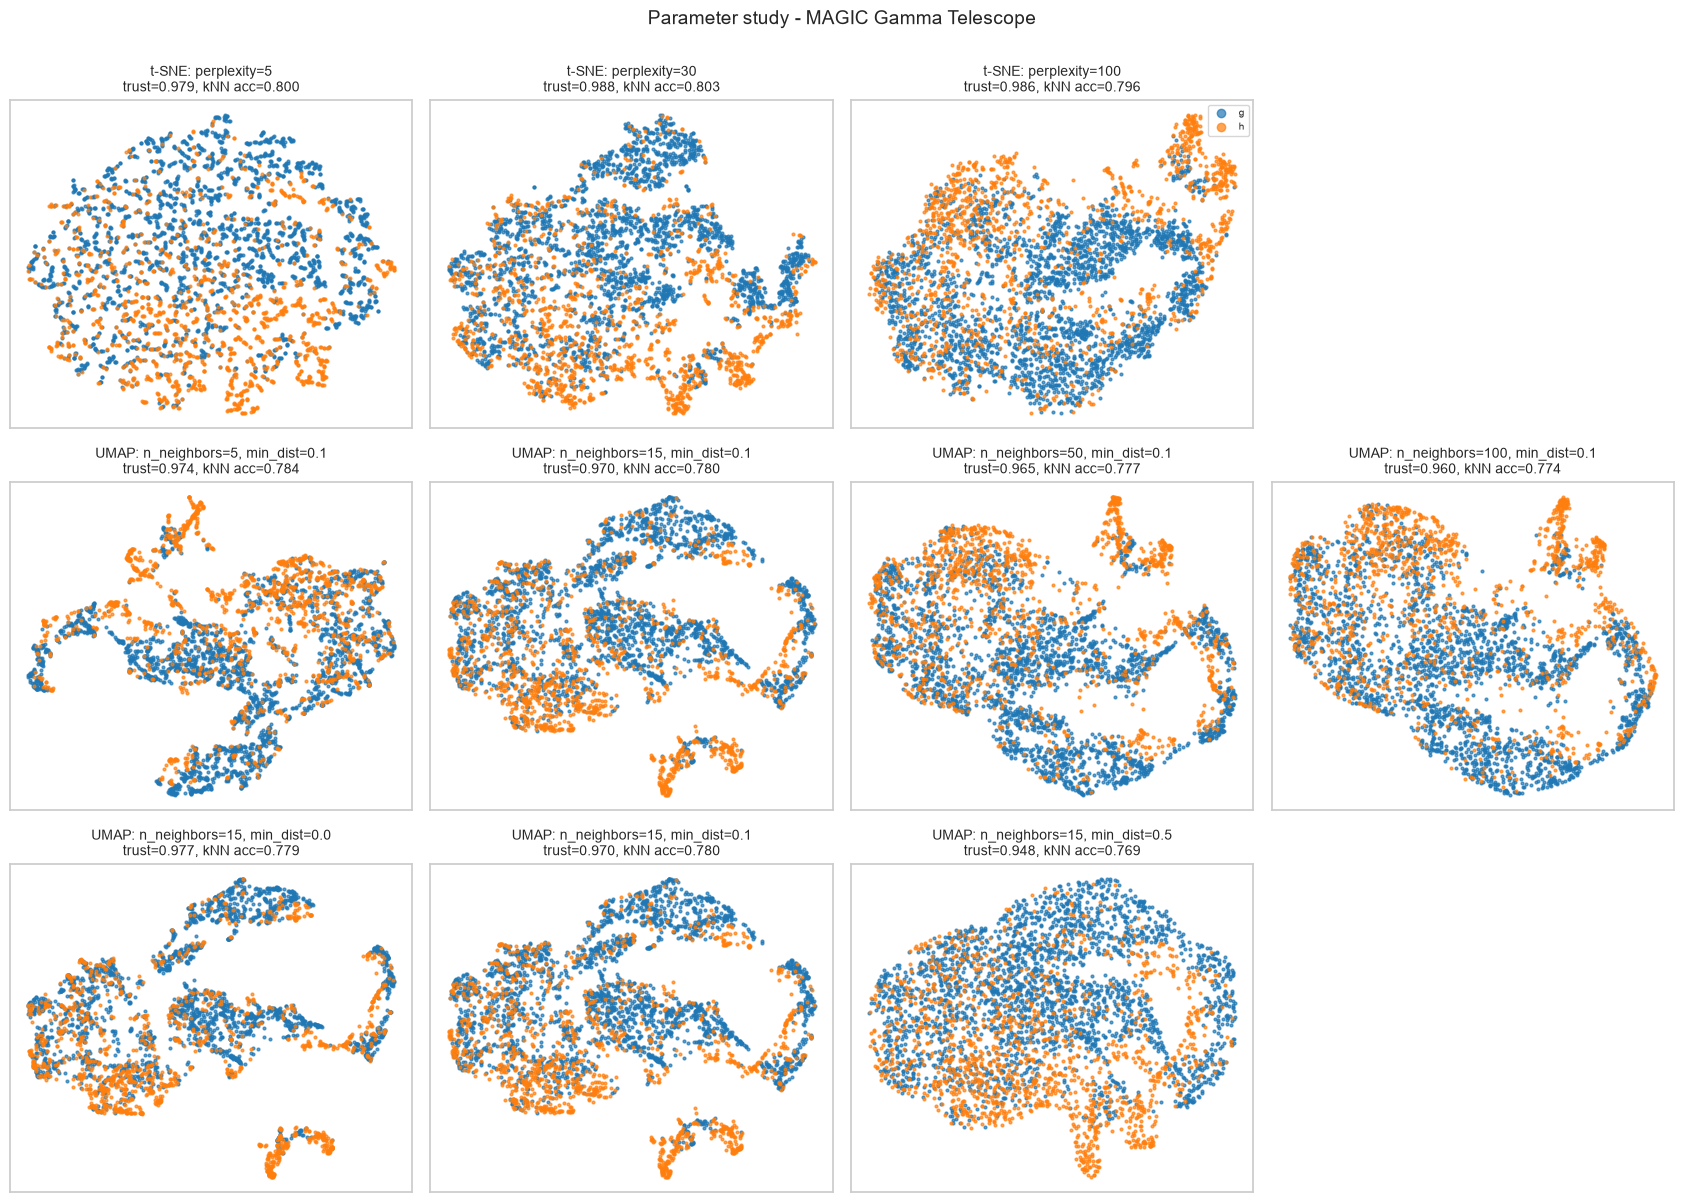

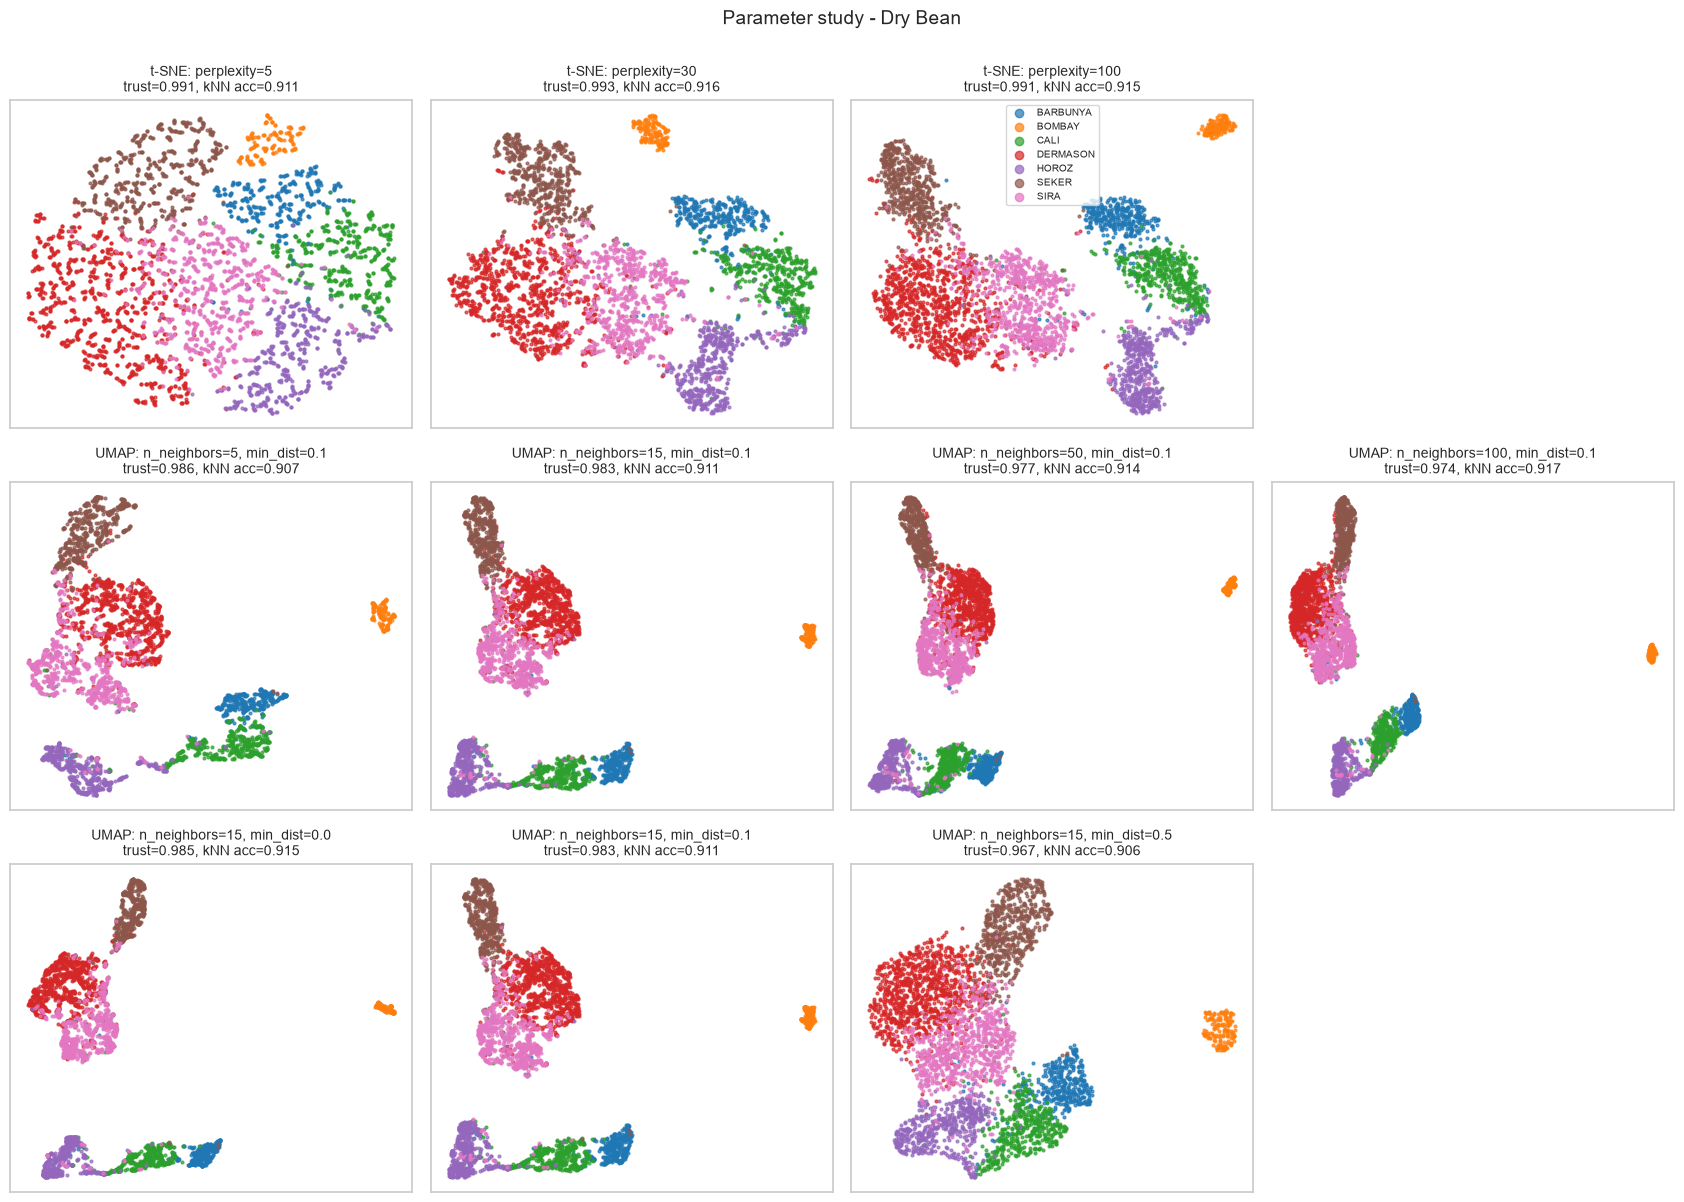

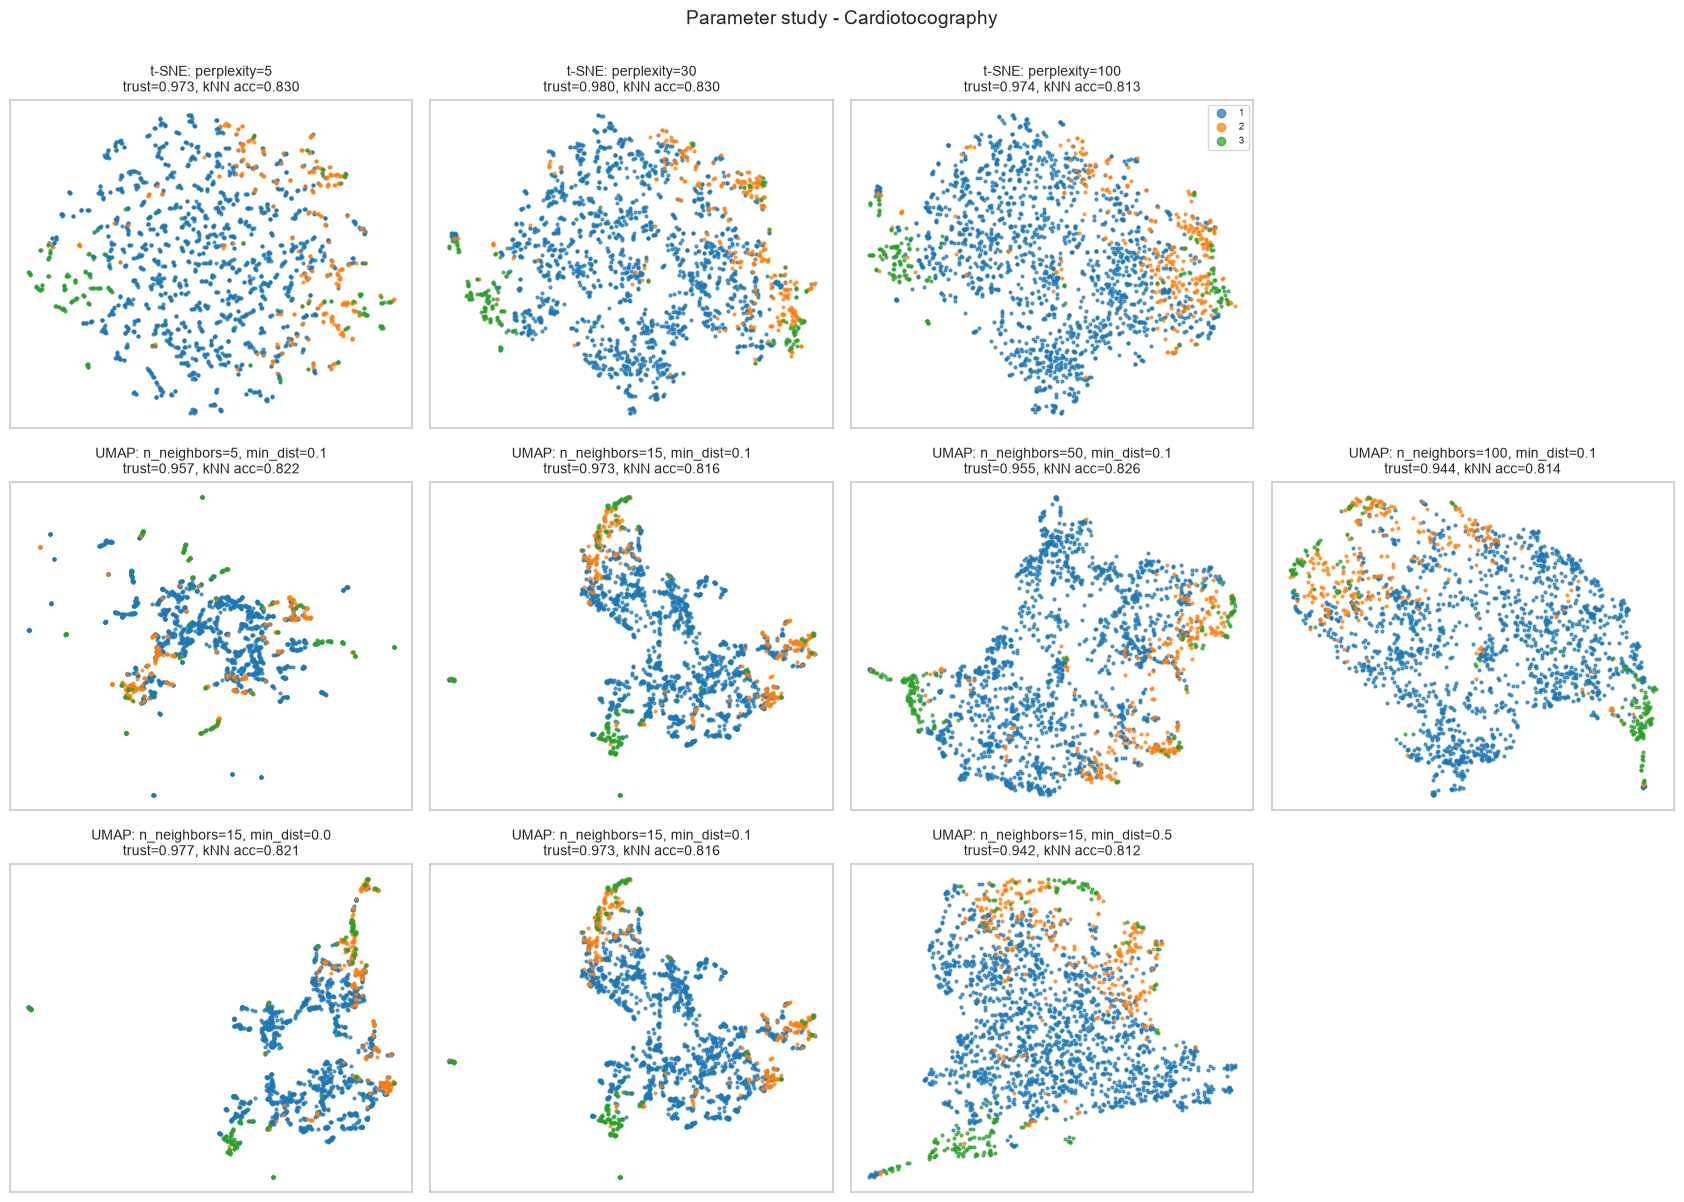

trustworthiness  continuity  knn_acc_2d  silhouette_2d
dataset               method setting                                                                              
MAGIC Gamma Telescope t-SNE  perplexity=5                             0.979       0.958       0.800          0.084
                             perplexity=30                            0.988       0.964       0.803          0.080
                             perplexity=100                           0.986       0.967       0.796          0.081
                      UMAP   n_neighbors=5, min_dist=0.1              0.974       0.960       0.784          0.058
                             n_neighbors=15, min_dist=0.1             0.970       0.971       0.780          0.061
                             n_neighbors=50, min_dist=0.1             0.965       0.974       0.777          0.060
                             n_neighbors=100, min_dist=0.1            0.960       0.975       0.774          0.063
                             n_neighbors=15, min_dist=0.0             0.977       0.967       0.779          0.063
                             n_neighbors=15, min_dist=0.5             0.948       0.977       0.769          0.058
Dry Bean              t-SNE  perplexity=5                             0.991       0.976       0.911          0.269
                             perplexity=30                            0.993       0.982       0.916          0.392
                             perplexity=100                           0.991       0.983       0.915          0.432
                      UMAP   n_neighbors=5, min_dist=0.1              0.986       0.978       0.907          0.416
                             n_neighbors=15, min_dist=0.1             0.983       0.983       0.912          0.449
                             n_neighbors=50, min_dist=0.1             0.977       0.984       0.914          0.442
                             n_neighbors=100, min_dist=0.1            0.974       0.985       0.917          0.444
                             n_neighbors=15, min_dist=0.0             0.985       0.980       0.915          0.464
                             n_neighbors=15, min_dist=0.5             0.967       0.989       0.906          0.376
Cardiotocography      t-SNE  perplexity=5                             0.973       0.957       0.830          0.079
                             perplexity=30                            0.980       0.963       0.830          0.095
                             perplexity=100                           0.974       0.963       0.813          0.101
                      UMAP   n_neighbors=5, min_dist=0.1              0.957       0.886       0.822          0.089
                             n_neighbors=15, min_dist=0.1             0.973       0.959       0.816          0.153
                             n_neighbors=50, min_dist=0.1             0.955       0.967       0.826          0.100
                             n_neighbors=100, min_dist=0.1            0.944       0.969       0.814          0.102
                             n_neighbors=15, min_dist=0.0             0.977       0.957       0.821          0.154
                             n_neighbors=15, min_dist=0.5             0.942       0.967       0.812          0.108

In [7]:
tsne_perps = [5, 30, 100]
umap_nns   = [5, 15, 50, 100]
umap_mds   = [0.0, 0.1, 0.5]

grid = {}
for p in tsne_perps:
    grid[("t-SNE", f"perplexity={p}")] = dict(perplexity=p)
for nn in umap_nns:
    grid[("UMAP", f"n_neighbors={nn}, min_dist=0.1")] = dict(n_neighbors=nn, min_dist=0.1)
for md_ in umap_mds:
    grid[("UMAP", f"n_neighbors=15, min_dist={md_}")] = dict(n_neighbors=15, min_dist=md_)

defaults = {("t-SNE", "perplexity=30"): "t-SNE", ("UMAP", "n_neighbors=15, min_dist=0.1"): "UMAP"}

def fit_setting(name, method, setting, X, y, kwargs):
    Z = run_tsne(X, **kwargs) if method == "t-SNE" else run_umap(X, **kwargs)
    return (name, method, setting), Z, dr_metrics(X, Z, y)

jobs = [delayed(fit_setting)(name, m, s, d["X"], d["y"], kw)
        for name, d in data.items() for (m, s), kw in grid.items() if (m, s) not in defaults]
computed = {key: (Z, met) for key, Z, met in Parallel(n_jobs=-1, verbose=5)(jobs)}

default_met = dr_df.set_index(["dataset", "method"])
param_emb, param_met = {}, {}
for name in data:
    for (m, s) in grid:
        key = (name, m, s)
        if (m, s) in defaults:
            param_emb[key] = emb[name][defaults[(m, s)]]
            param_met[key] = default_met.loc[(name, defaults[(m, s)])].to_dict()
        else:
            param_emb[key], param_met[key] = computed[key]

for name, d in data.items():
    rows_keys = [
        [(name, "t-SNE", f"perplexity={p}") for p in tsne_perps],
        [(name, "UMAP", f"n_neighbors={nn}, min_dist=0.1") for nn in umap_nns],
        [(name, "UMAP", f"n_neighbors=15, min_dist={m}") for m in umap_mds],
    ]
    fig, axes = plt.subplots(3, 4, figsize=(17, 12))
    for r, keys in enumerate(rows_keys):
        for c in range(4):
            ax = axes[r, c]
            if c >= len(keys):
                ax.axis("off"); continue
            k = keys[c]
            scatter_labels(ax, param_emb[k], d["y"],
                           f"{k[1]}: {k[2]}\ntrust={param_met[k]['trustworthiness']:.3f}, kNN acc={param_met[k]['knn_acc_2d']:.3f}",
                           d["classes"], s=4, legend=(r == 0 and c == 2))
    fig.suptitle(f"Parameter study - {name}", fontsize=14, y=1.0)
    plt.tight_layout()
    plt.show()

param_df = (pd.DataFrame([dict(dataset=k[0], method=k[1], setting=k[2], **v) for k, v in param_met.items()])
              .set_index(["dataset", "method", "setting"]).round(3))
display(param_df)

**Discussion: parameter effects** 

t-SNE perplexity 30 gives the highest trustworthiness on all three datasets (0.988 / 0.993 / 0.980); perplexity 5 gives a diffuse cloud with less distinct groups (Dry Bean silhouette 0.269 vs 0.392) and 100 changes trustworthiness and kNN accuracy little but tightens the Dry Bean groups (silhouette 0.432). For UMAP, increasing `n_neighbors` from 15 lowers trustworthiness and raises continuity on all datasets, so small values favour local detail and large values the global arrangement, and `n_neighbors = 5` is poor on Cardiotocography (continuity 0.886). Larger `min_dist` spreads the points and lowers trustworthiness (0.0 vs 0.5: 0.977 / 0.948 on MAGIC, 0.985 / 0.967 on Dry Bean, 0.977 / 0.942 on Cardiotocography) while kNN accuracy is minimally changed, so it mainly changes visual density.

### Which technique is most suitable for each dataset?

In [8]:
summary = dr_df.set_index(["dataset", "method"])
verdict = []
for name in data:
    sub = summary.loc[name]
    ranks = sub[["trustworthiness", "continuity", "knn_acc_2d"]].rank(ascending=False).mean(axis=1)
    verdict.append(dict(
        dataset=name,
        best_trustworthiness=sub.trustworthiness.idxmax(),
        best_continuity=sub.continuity.idxmax(),
        best_class_separation_kNN=sub.knn_acc_2d.idxmax(),
        best_overall_mean_rank=ranks.idxmin(),
    ))
display(pd.DataFrame(verdict).set_index("dataset"))

,best_trustworthiness,best_continuity,best_class_separation_kNN,best_overall_mean_rank
dataset,,,,
MAGIC Gamma Telescope,t-SNE,UMAP,t-SNE,t-SNE
Dry Bean,t-SNE,PCA,t-SNE,t-SNE
Cardiotocography,t-SNE,t-SNE,t-SNE,t-SNE


**Discussion: which technique, per dataset**

On MAGIC, t-SNE has the best trustworthiness and kNN accuracy, but gamma and hadron overlap heavily in every embedding (silhouette <= 0.11) and only some hadron-rich pockets stand out, so t-SNE is most suitable with modest separation. On Dry Bean, t-SNE and UMAP clearly beat PCA (kNN 0.916 / 0.912 vs 0.859) and give compact, distinct groups with Bombay isolated; t-SNE is more faithful (0.993 vs 0.983) and ranks first overall, while UMAP has the best class silhouette and places related varieties together (Barbunya-Cali-Horoz in one arm, Dermason-Sira-Seker in another). On Cardiotocography, all kNN accuracies (0.816-0.830) are only slightly above the majority-class rate (0.78) and pathologic and suspect cases form only small pockets at the edge of the normal group, so no method separates the classes; t-SNE is the most faithful (0.980).

The methods differ mainly in structure: PCA squeezes high-dimensional neighbourhoods together (trustworthiness 0.86-0.94 vs 0.97-0.99), t-SNE spreads the points into broad, locally clumped regions, and UMAP gives more compact, more clearly separated groups; distances between clusters and cluster sizes in t-SNE and UMAP are not meaningful. Overall t-SNE is most suitable on all three by trustworthiness and mean rank, with UMAP a close second (UMAP with `min_dist = 0.0` reaches 0.977 / 0.985 / 0.977 vs t-SNE 0.988 / 0.993 / 0.980), and where classes overlap in the original space no 2D method can create separation that is not in the data.

## Clustering

K-Means, DBSCAN and hierarchical clustering run on the original standardised data, and UMAP (default parameters) is used only to visualise the result. Internal quality is measured with silhouette and Davies-Bouldin (DBSCAN noise excluded and reported as a noise fraction), external quality with ARI and NMI against the true classes (DBSCAN noise counts as one extra cluster).

In [9]:
def cluster_metrics(X, y, labels):
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    out = dict(n_clusters=n_clusters, noise=float(1 - mask.mean()))
    if n_clusters >= 2 and mask.sum() > n_clusters:
        out["silhouette"] = silhouette_score(X[mask], labels[mask])
        out["davies_bouldin"] = davies_bouldin_score(X[mask], labels[mask])
    else:
        out["silhouette"] = np.nan
        out["davies_bouldin"] = np.nan
    out["ARI"] = adjusted_rand_score(y, labels)
    out["NMI"] = normalized_mutual_info_score(y, labels)
    return out

n_true = {name: len(np.unique(d["y"])) for name, d in data.items()}
print(n_true)

{'MAGIC Gamma Telescope': 2, 'Dry Bean': 7, 'Cardiotocography': 3}


### K-Means: influence of `k`

`k` = 2 ... 10 with `n_init = 10`; the dashed line marks the true number of classes.

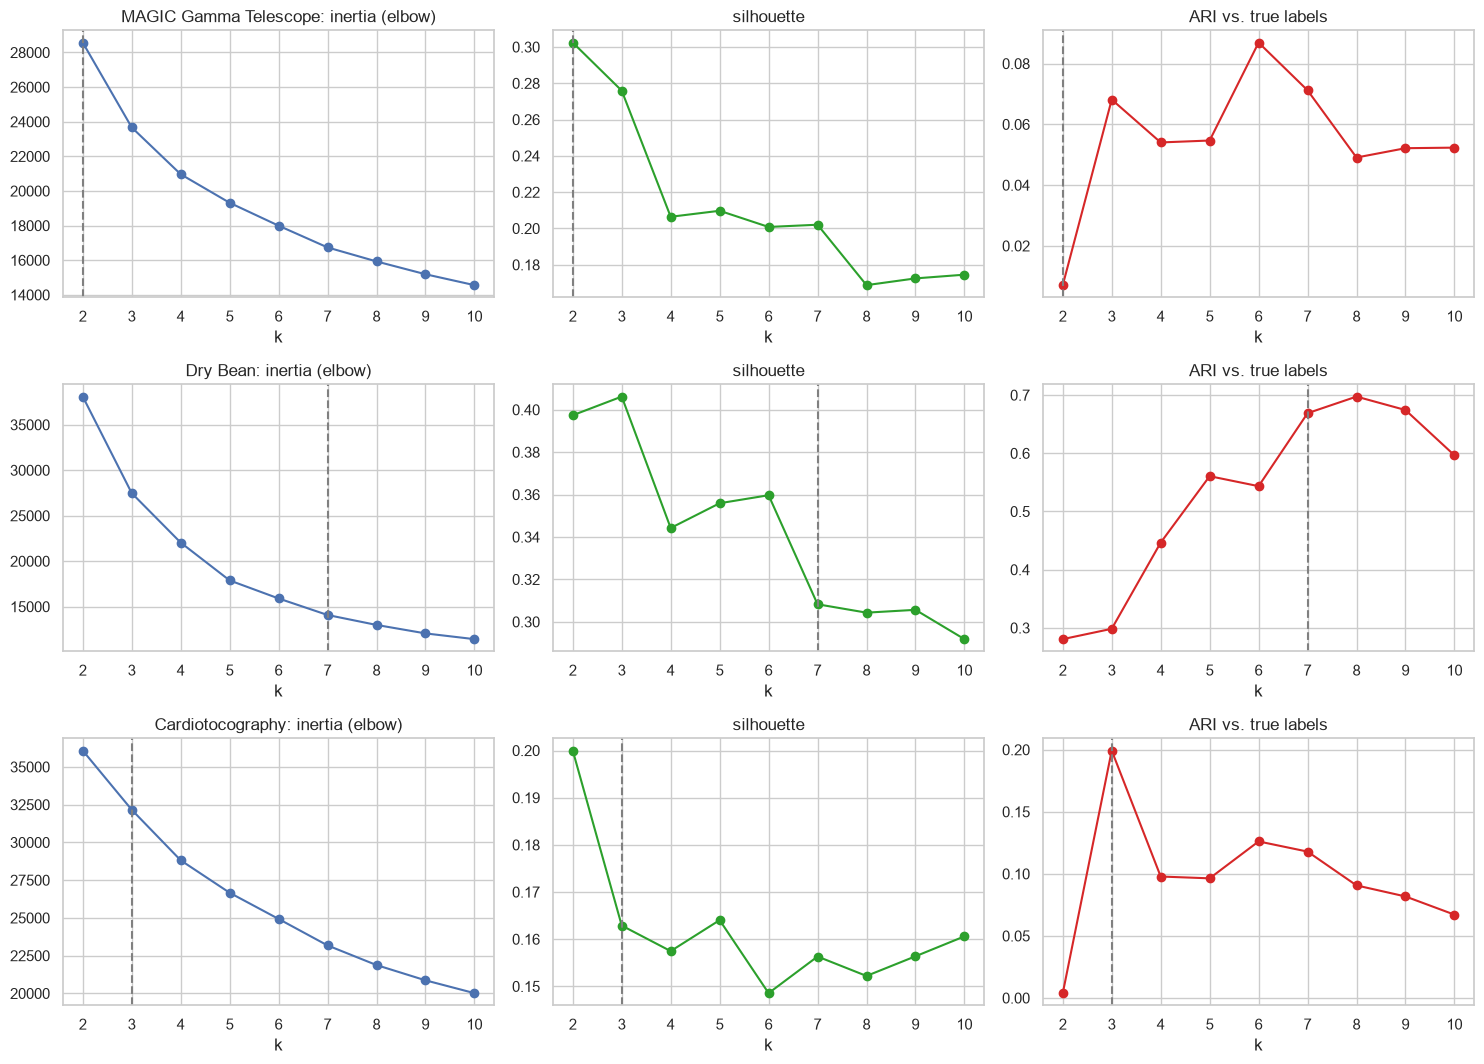

inertia  n_clusters  noise  silhouette  davies_bouldin    ARI    NMI
dataset               k                                                                         
MAGIC Gamma Telescope 2   28569.930           2    0.0       0.302           1.423  0.007  0.002
                      3   23670.682           3    0.0       0.276           1.427  0.068  0.093
                      4   20965.715           4    0.0       0.206           1.490  0.054  0.073
                      5   19317.637           5    0.0       0.210           1.541  0.055  0.079
                      6   17994.572           6    0.0       0.201           1.521  0.087  0.100
                      7   16739.126           7    0.0       0.202           1.538  0.071  0.087
                      8   15929.561           8    0.0       0.169           1.508  0.049  0.077
                      9   15190.366           9    0.0       0.172           1.487  0.052  0.080
                      10  14560.339          10    0.0       0.175           1.487  0.052  0.084
Dry Bean              2   38093.599           2    0.0       0.397           1.078  0.281  0.434
                      3   27478.765           3    0.0       0.406           0.892  0.298  0.489
                      4   22041.939           4    0.0       0.344           0.920  0.447  0.605
                      5   17882.683           5    0.0       0.356           1.026  0.561  0.700
                      6   15898.563           6    0.0       0.360           0.988  0.543  0.670
                      7   14081.883           7    0.0       0.308           1.094  0.669  0.717
                      8   12988.361           8    0.0       0.304           1.145  0.697  0.731
                      9   12057.341           9    0.0       0.306           1.151  0.674  0.720
                      10  11426.257          10    0.0       0.292           1.195  0.597  0.689
Cardiotocography      2   36078.913           2    0.0       0.200           1.935  0.004  0.063
                      3   32159.915           3    0.0       0.163           1.898  0.199  0.203
                      4   28813.272           4    0.0       0.157           1.740  0.098  0.188
                      5   26663.789           5    0.0       0.164           1.474  0.096  0.185
                      6   24930.449           6    0.0       0.149           1.573  0.126  0.230
                      7   23176.054           7    0.0       0.156           1.448  0.118  0.208
                      8   21875.937           8    0.0       0.152           1.567  0.091  0.201
                      9   20865.247           9    0.0       0.156           1.569  0.082  0.212
                      10  20016.174          10    0.0       0.161           1.583  0.067  0.204

In [10]:
km_rows = []
for name, d in data.items():
    X, y = d["X"], d["y"]
    for k in range(2, 11):
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        km_rows.append(dict(dataset=name, k=k, inertia=km.inertia_, **cluster_metrics(X, y, km.labels_)))
km_df = pd.DataFrame(km_rows)

fig, axes = plt.subplots(len(data), 3, figsize=(15, 3.6 * len(data)))
for r, name in enumerate(data):
    sub = km_df[km_df.dataset == name]
    axes[r, 0].plot(sub.k, sub.inertia, "o-"); axes[r, 0].set_title(f"{name}: inertia (elbow)")
    axes[r, 1].plot(sub.k, sub.silhouette, "o-", color="tab:green"); axes[r, 1].set_title("silhouette")
    axes[r, 2].plot(sub.k, sub.ARI, "o-", color="tab:red"); axes[r, 2].set_title("ARI vs. true labels")
    for c in range(3):
        axes[r, c].axvline(n_true[name], ls="--", color="gray")
        axes[r, c].set_xlabel("k")
plt.tight_layout()
plt.show()

display(km_df.set_index(["dataset", "k"]).round(3))

### DBSCAN: influence of `eps` and `min_samples`

The grid covers `min_samples` in {5, 10, 20} and 12 `eps` values from the 40-97% quantiles of the k-nearest-neighbour distances; the k-distance plot (`min_samples = 10`) shows the elbow heuristic.

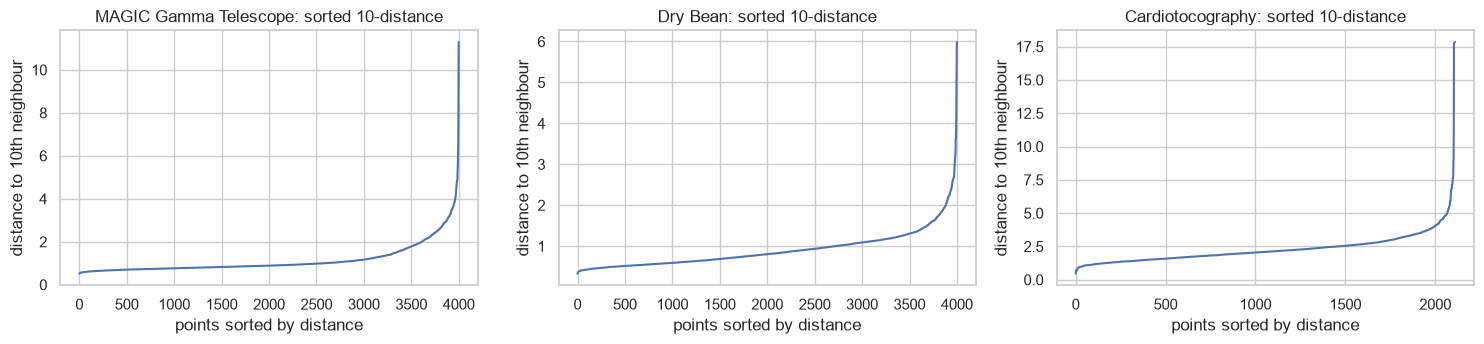

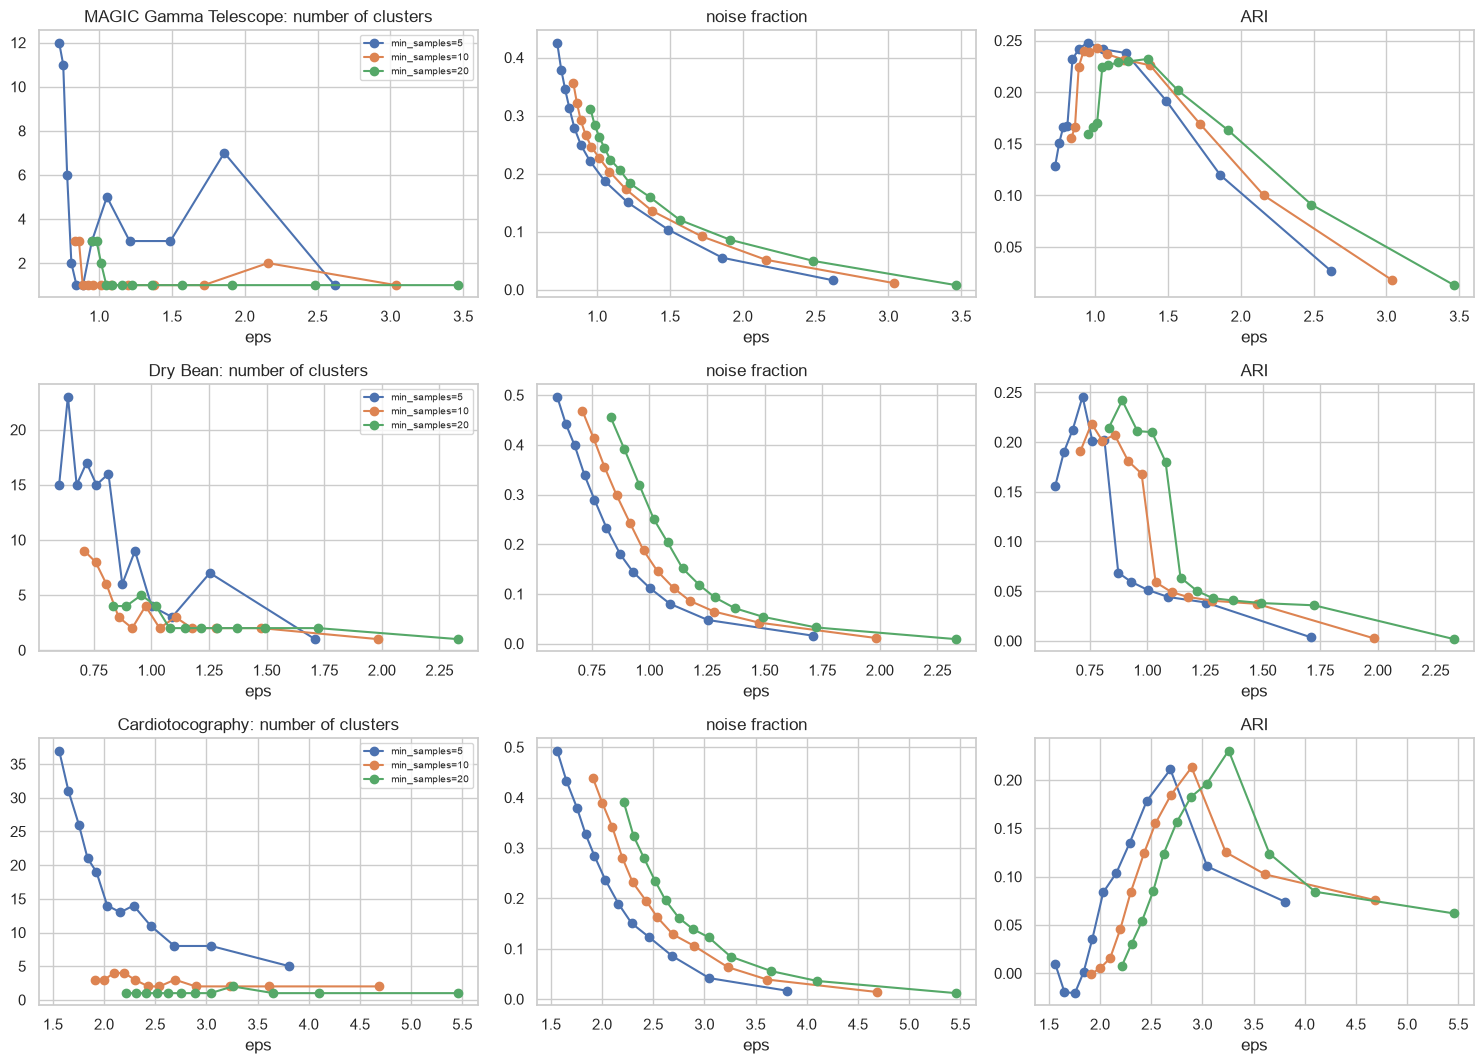

n_clusters  noise  silhouette  davies_bouldin    ARI    NMI
dataset               min_samples eps                                                               
MAGIC Gamma Telescope 5           0.726          12  0.426      -0.296           1.183  0.129  0.113
                                  0.754          11  0.379      -0.187           1.043  0.151  0.119
                                  0.781           6  0.345      -0.093           0.859  0.166  0.127
                                  0.810           2  0.313       0.294           0.982  0.168  0.127
                                  0.845           1  0.278         NaN             NaN  0.232  0.141
...                                             ...    ...         ...             ...    ...    ...
Cardiotocography      20          3.042           1  0.123         NaN             NaN  0.196  0.116
                                  3.257           2  0.084       0.296           0.899  0.230  0.157
                                  3.656           1  0.055         NaN             NaN  0.124  0.061
                                  4.103           1  0.036         NaN             NaN  0.084  0.047
                                  5.459           1  0.012         NaN             NaN  0.062  0.053

[108 rows x 6 columns]

In [11]:
ms_list = [5, 10, 20]
db_rows = []
kdist = {}
for name, d in data.items():
    X, y = d["X"], d["y"]
    for ms in ms_list:
        dist = NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)[0][:, -1]
        kd = np.sort(dist)
        if ms == 10:
            kdist[name] = kd
        for q in np.linspace(0.40, 0.97, 12):
            eps = float(np.quantile(kd, q))
            lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
            db_rows.append(dict(dataset=name, min_samples=ms, eps=round(eps, 3), **cluster_metrics(X, y, lab)))
db_df = pd.DataFrame(db_rows)

fig, axes = plt.subplots(1, len(data), figsize=(15, 3.6))
for ax, name in zip(axes, data):
    ax.plot(kdist[name]); ax.set_title(f"{name}: sorted 10-distance")
    ax.set_xlabel("points sorted by distance"); ax.set_ylabel("distance to 10th neighbour")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(data), 3, figsize=(15, 3.6 * len(data)))
for r, name in enumerate(data):
    sub = db_df[db_df.dataset == name]
    for ms in ms_list:
        s2 = sub[sub.min_samples == ms]
        axes[r, 0].plot(s2.eps, s2.n_clusters, "o-", label=f"min_samples={ms}")
        axes[r, 1].plot(s2.eps, s2.noise, "o-")
        axes[r, 2].plot(s2.eps, s2.ARI, "o-")
    axes[r, 0].set_title(f"{name}: number of clusters"); axes[r, 1].set_title("noise fraction"); axes[r, 2].set_title("ARI")
    axes[r, 0].legend(fontsize=7)
    for c in range(3):
        axes[r, c].set_xlabel("eps")
plt.tight_layout()
plt.show()

display(db_df.set_index(["dataset", "min_samples", "eps"]).round(3))

**Choosing DBSCAN parameters (no labels used):** highest silhouette (noise excluded) among configurations with 2-20 clusters and at most 50% noise, falling back to `min_samples = 10` and the 90th percentile k-distance for `eps`. This silhouette ignores noise and can reward degenerate solutions, so the noise fraction is always reported.

In [12]:
def pick_dbscan(name):
    sub = db_df[db_df.dataset == name]
    ok = sub[(sub.n_clusters >= 2) & (sub.n_clusters <= 20) & (sub.noise <= 0.5) & sub.silhouette.notna()]
    if len(ok):
        best = ok.loc[ok.silhouette.idxmax()]
        return float(best.eps), int(best.min_samples)
    return float(np.quantile(kdist[name], 0.90)), 10

db_choice = {name: pick_dbscan(name) for name in data}
print({k: dict(eps=round(v[0], 3), min_samples=v[1]) for k, v in db_choice.items()})

{'MAGIC Gamma Telescope': {'eps': 2.159, 'min_samples': 10}, 'Dry Bean': {'eps': 1.144, 'min_samples': 20}, 'Cardiotocography': {'eps': 3.229, 'min_samples': 10}}


**Reference (uses the labels, so not a selectable setting):** the grid configuration with the highest ARI per dataset and the share of non-noise points in its largest cluster.

In [13]:
ref_rows = []
for name, d in data.items():
    X, y = d["X"], d["y"]
    sub = db_df[db_df.dataset == name]
    best = sub.loc[sub.ARI.idxmax()]
    eps_b, ms_b = float(best.eps), int(best.min_samples)
    lab = DBSCAN(eps=eps_b, min_samples=ms_b).fit_predict(X)
    kept = lab[lab != -1]
    m = cluster_metrics(X, y, lab)
    ref_rows.append(dict(dataset=name, eps=round(eps_b, 3), min_samples=ms_b, n_clusters=m["n_clusters"],
                         noise=m["noise"], largest_cluster_share=np.bincount(kept).max() / len(kept),
                         ARI=m["ARI"], NMI=m["NMI"]))
display(pd.DataFrame(ref_rows).set_index("dataset").round(3))

,eps,min_samples,n_clusters,noise,largest_cluster_share,ARI,NMI
dataset,,,,,,,
MAGIC Gamma Telescope,0.951,5,3,0.222,0.997,0.248,0.162
Dry Bean,0.719,5,17,0.339,0.816,0.246,0.412
Cardiotocography,3.257,20,2,0.084,0.990,0.230,0.157


### Hierarchical clustering: influence of linkage

The tree is cut at the true number of classes for Ward, complete, average and single linkage; the dendrogram is a truncated Ward dendrogram of a 1500-point subsample.

min_cluster_share  n_clusters  noise  silhouette  davies_bouldin    ARI    NMI
dataset               linkage                                                                                 
MAGIC Gamma Telescope ward                  0.208           2    0.0       0.349           1.539  0.052  0.017
                      complete              0.000           2    0.0       0.749           0.572  0.001  0.002
                      average               0.000           2    0.0       0.749           0.572  0.001  0.002
                      single                0.000           2    0.0       0.723           0.197  0.000  0.001
Dry Bean              ward                  0.019           7    0.0       0.272           1.104  0.668  0.728
                      complete              0.012           7    0.0       0.327           1.165  0.532  0.663
                      average               0.000           7    0.0       0.193           0.772  0.033  0.169
                      single                0.000           7    0.0       0.281           0.387  0.001  0.005
Cardiotocography      ward                  0.054           3    0.0       0.145           1.787  0.333  0.257
                      complete              0.002           3    0.0       0.512           0.594  0.019  0.018
                      average               0.003           3    0.0       0.516           0.627  0.041  0.041
                      single                0.001           3    0.0       0.682           0.317  0.016  0.019

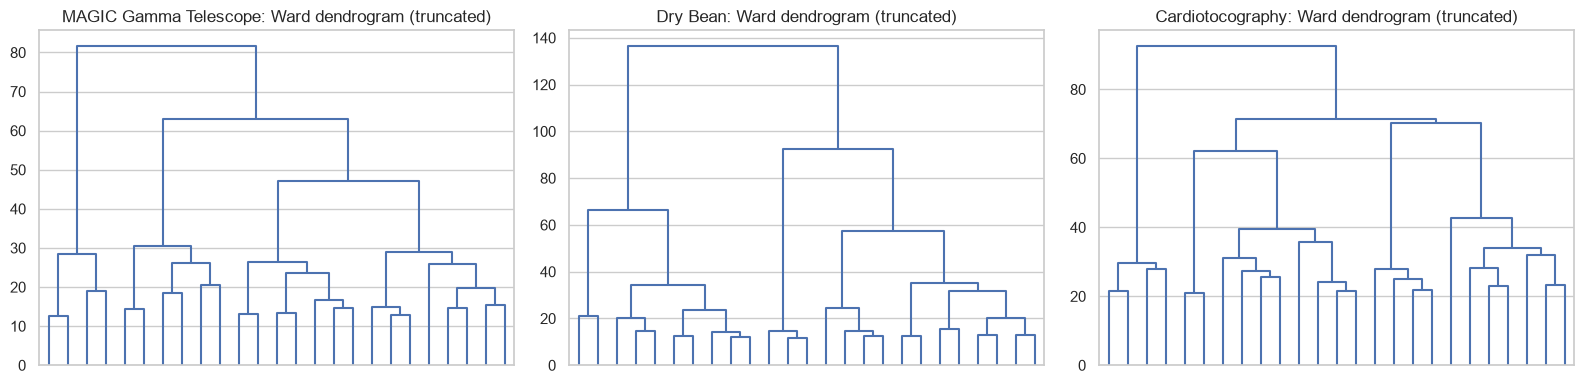

In [14]:
link_rows = []
link_labels = {}
for name, d in data.items():
    X, y = d["X"], d["y"]
    for link in ["ward", "complete", "average", "single"]:
        lab = AgglomerativeClustering(n_clusters=n_true[name], linkage=link).fit_predict(X)
        link_labels[(name, link)] = lab
        sizes = np.bincount(lab)
        link_rows.append(dict(dataset=name, linkage=link, min_cluster_share=sizes.min() / len(lab),
                              **cluster_metrics(X, y, lab)))
link_df = pd.DataFrame(link_rows)
display(link_df.set_index(["dataset", "linkage"]).round(3))

fig, axes = plt.subplots(1, len(data), figsize=(16, 4))
for ax, (name, d) in zip(axes, data.items()):
    Z = linkage(d["X"][:1500], method="ward")
    dendrogram(Z, truncate_mode="lastp", p=25, no_labels=True, ax=ax, color_threshold=0)
    ax.set_title(f"{name}: Ward dendrogram (truncated)")
plt.tight_layout()
plt.show()

**Choosing the linkage:** best silhouette among linkages whose smallest cluster holds at least 2% of the points, since single and average linkage chain into one giant cluster; Ward is used if none qualifies (the case for Dry Bean, where Ward's smallest cluster holds 1.9%).

In [15]:
def pick_linkage(name):
    sub = link_df[(link_df.dataset == name) & (link_df.min_cluster_share >= 0.02) & link_df.silhouette.notna()]
    return sub.loc[sub.silhouette.idxmax()].linkage if len(sub) else "ward"

link_choice = {name: pick_linkage(name) for name in data}
print(link_choice)

{'MAGIC Gamma Telescope': 'ward', 'Dry Bean': 'ward', 'Cardiotocography': 'ward'}


### Final comparison of the three clustering techniques

In [16]:
final_labels, final_rows = {}, []
for name, d in data.items():
    X, y = d["X"], d["y"]
    K = n_true[name]
    eps, ms = db_choice[name]
    final_labels[name] = {
        f"K-Means (k={K})": KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(X),
        f"DBSCAN (eps={eps:.2f}, min_samples={ms})": DBSCAN(eps=eps, min_samples=ms).fit_predict(X),
        f"Hierarchical ({link_choice[name]}, k={K})": link_labels[(name, link_choice[name])],
    }
    for m, lab in final_labels[name].items():
        final_rows.append(dict(dataset=name, method=m, **cluster_metrics(X, y, lab)))
final_df = pd.DataFrame(final_rows)
display(final_df.set_index(["dataset", "method"]).round(3))

n_clusters  noise  silhouette  davies_bouldin    ARI    NMI
dataset               method                                                                                        
MAGIC Gamma Telescope K-Means (k=2)                               2  0.000       0.302           1.423  0.007  0.002
                      DBSCAN (eps=2.16, min_samples=10)           2  0.051       0.548           0.539  0.100  0.125
                      Hierarchical (ward, k=2)                    2  0.000       0.349           1.539  0.052  0.017
Dry Bean              K-Means (k=7)                               7  0.000       0.308           1.094  0.669  0.717
                      DBSCAN (eps=1.14, min_samples=20)           2  0.151       0.593           0.380  0.064  0.132
                      Hierarchical (ward, k=7)                    7  0.000       0.272           1.104  0.668  0.728
Cardiotocography      K-Means (k=3)                               3  0.000       0.163           1.898  0.199  0.203
                      DBSCAN (eps=3.23, min_samples=10)           2  0.063       0.498           0.619  0.125  0.060
                      Hierarchical (ward, k=3)                    3  0.000       0.145           1.787  0.333  0.257

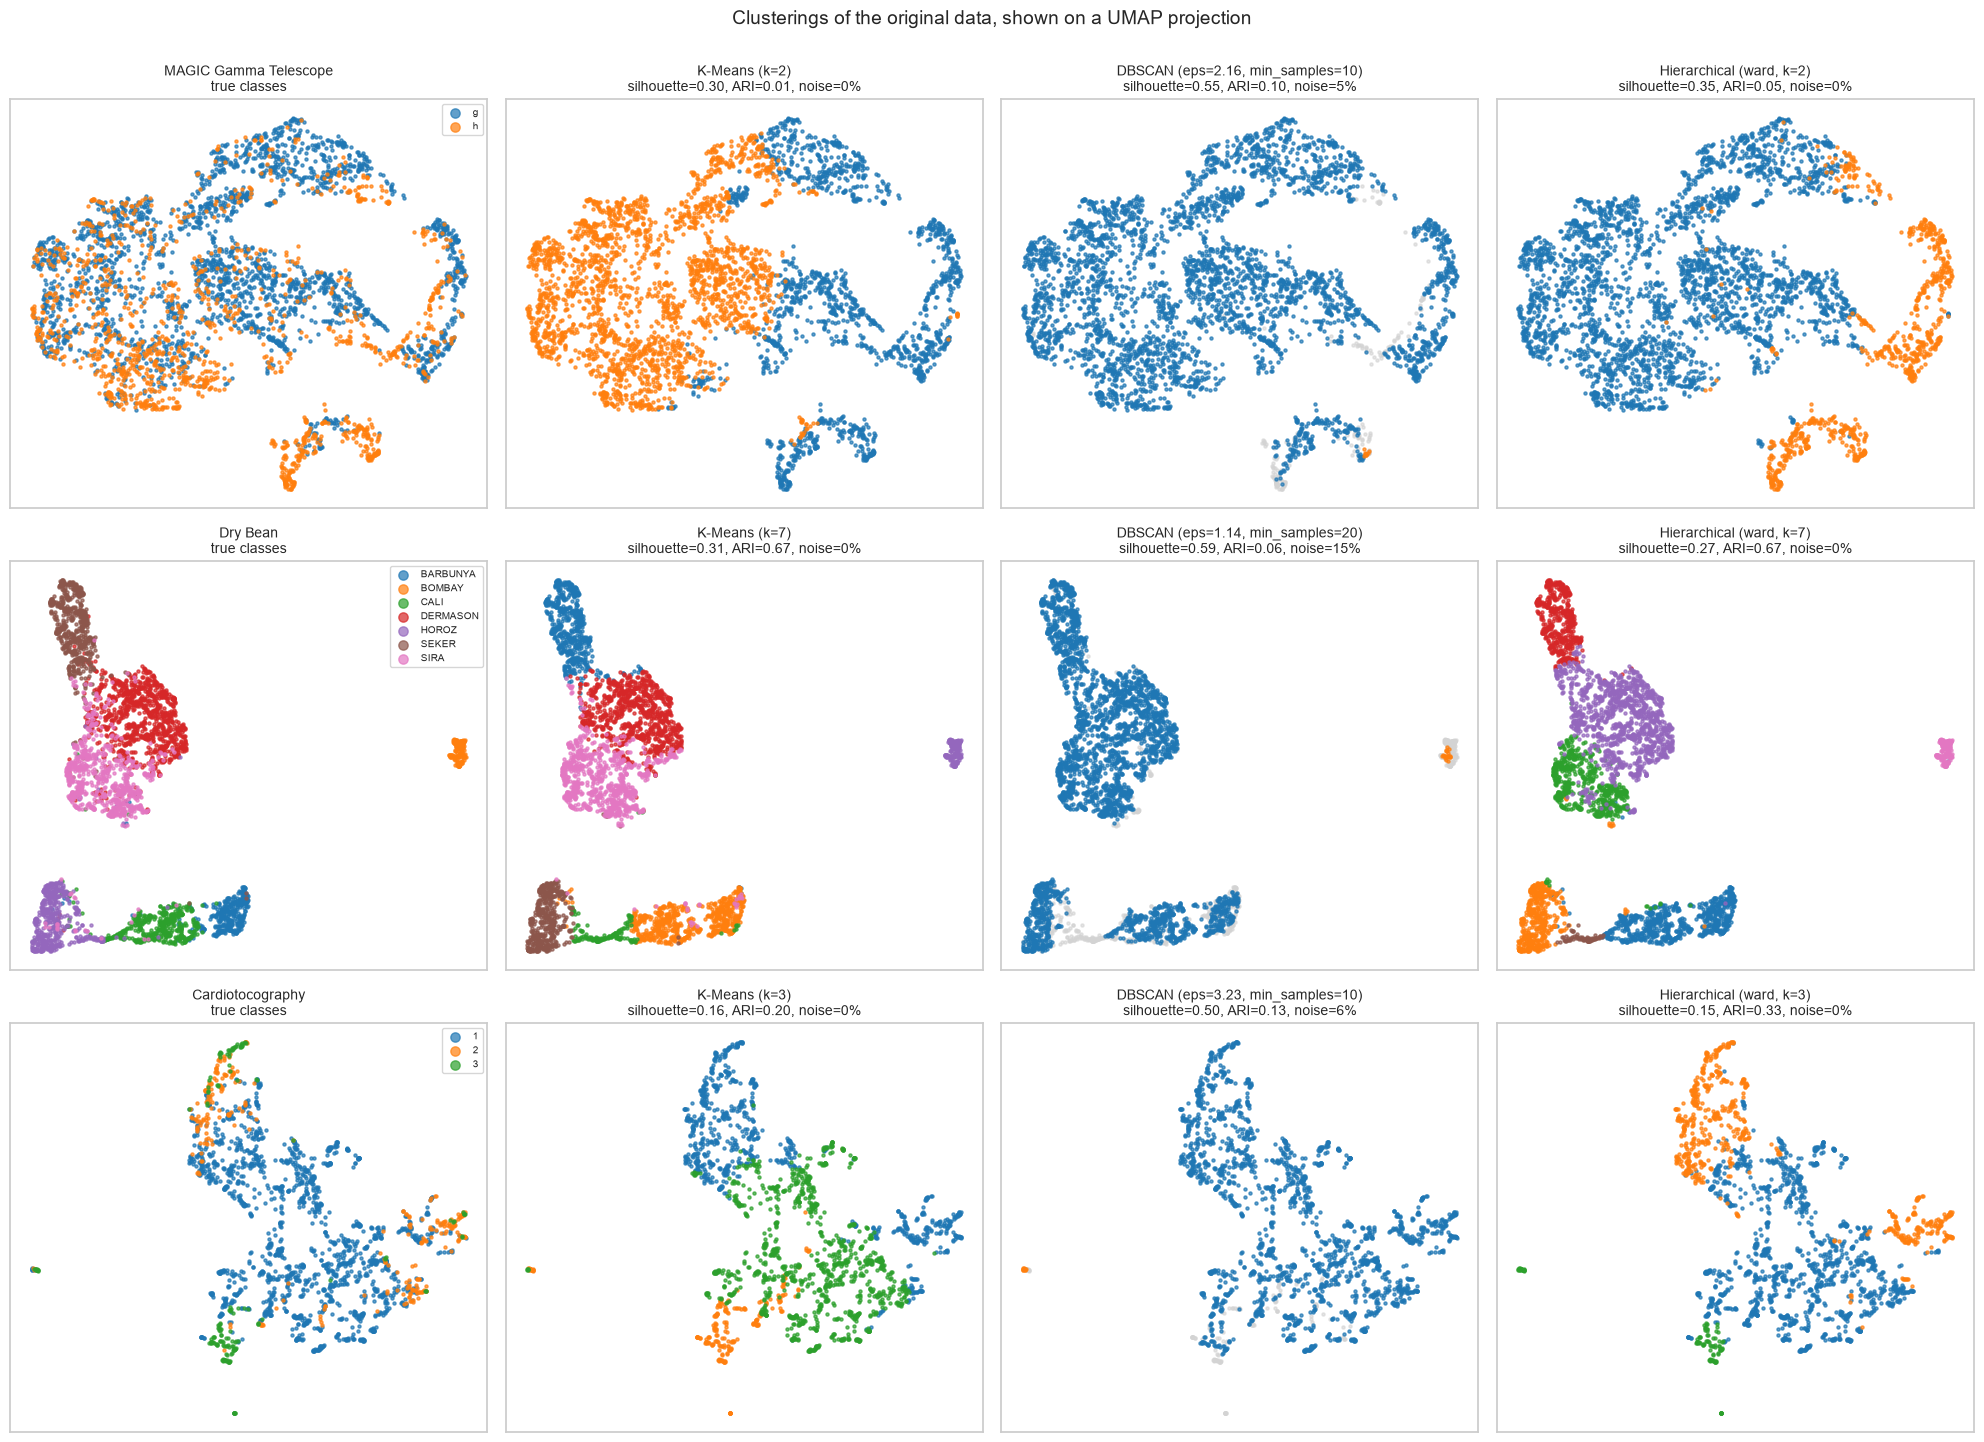

In [17]:
fig, axes = plt.subplots(len(data), 4, figsize=(20, 4.8 * len(data)))
for r, (name, d) in enumerate(data.items()):
    Z = emb[name]["UMAP"]
    scatter_labels(axes[r, 0], Z, d["y"], f"{name}\ntrue classes", d["classes"], legend=True)
    for c, (m, lab) in enumerate(final_labels[name].items(), start=1):
        row = final_df[(final_df.dataset == name) & (final_df.method == m)].iloc[0]
        sil = f"{row.silhouette:.2f}" if pd.notna(row.silhouette) else "n/a"
        scatter_labels(axes[r, c], Z, lab, f"{m}\nsilhouette={sil}, ARI={row.ARI:.2f}, noise={row.noise:.0%}")
plt.suptitle("Clusterings of the original data, shown on a UMAP projection", fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

In [18]:
for name, d in data.items():
    for m, lab in final_labels[name].items():
        ct = pd.crosstab(pd.Series(lab, name="cluster"),
                         pd.Series([d["classes"][i] for i in d["y"]], name="true class"))
        print(f"{name} | {m}")
        display(ct)

MAGIC Gamma Telescope | K-Means (k=2)


true class,g,h
cluster,,
0,998,599
1,1611,792


MAGIC Gamma Telescope | DBSCAN (eps=2.16, min_samples=10)


true class,g,h
cluster,,
-1,4,202
0,2605,1179
1,0,10


MAGIC Gamma Telescope | Hierarchical (ward, k=2)


...

true class,1,2,3
cluster,,,
0,511,241,62
1,104,15,109
2,1030,35,4


Cardiotocography | DBSCAN (eps=3.23, min_samples=10)


true class,1,2,3
cluster,,,
-1,62,18,54
0,1571,271,121
1,12,2,0


Cardiotocography | Hierarchical (ward, k=3)


true class,1,2,3
cluster,,,
0,1265,66,22
1,366,219,58
2,14,6,95


In [19]:
verdict = []
for name in data:
    sub = final_df[final_df.dataset == name].set_index("method")
    verdict.append(dict(dataset=name,
                        best_silhouette=sub.silhouette.idxmax(),
                        best_ARI=sub.ARI.idxmax(),
                        best_NMI=sub.NMI.idxmax()))
display(pd.DataFrame(verdict).set_index("dataset"))

,best_silhouette,best_ARI,best_NMI
dataset,,,
MAGIC Gamma Telescope,"DBSCAN (eps=2.16, min_samples=10)","DBSCAN (eps=2.16, min_samples=10)","DBSCAN (eps=2.16, min_samples=10)"
Dry Bean,"DBSCAN (eps=1.14, min_samples=20)",K-Means (k=7),"Hierarchical (ward, k=7)"
Cardiotocography,"DBSCAN (eps=3.23, min_samples=10)","Hierarchical (ward, k=3)","Hierarchical (ward, k=3)"


**Discussion: clustering** 

K-Means recovers Dry Bean well (ARI 0.669 at k = 7, peak 0.697 at k = 8) although the silhouette peaks at k = 3, so internal scores alone do not find the true k; it fails on MAGIC (ARI 0.007) and is weak on Cardiotocography (0.199). DBSCAN is very sensitive to `eps`. The selected configurations put at least 99% of the non-noise points into one cluster, so their high silhouette (0.50-0.59, noise excluded) is an artefact and ARI is at most 0.13; even the best ARI configuration in the grid reaches only 0.248 / 0.246 / 0.230 (MAGIC / Dry Bean / Cardiotocography), as one dominant cluster plus noise on MAGIC and Cardiotocography and a large cluster (82%), 16 small ones and 34% noise on Dry Bean. ARI counts noise as its own cluster, so the MAGIC value reflects a noise-versus-rest split, not a recovery of the classes. A single global `eps` copes poorly with varying density in 10-21 dimensions, although its noise is informative on MAGIC (202 of 206 noise points are hadrons). Hierarchical clustering depends on the linkage: Ward behaves like K-Means (Dry Bean ARI 0.668 vs 0.669) and is best on Cardiotocography (ARI 0.333, NMI 0.257 vs 0.199, 0.203), while the other linkages chain into clusters below 2% of the data with inflated silhouette.

Compared with the true classes, Dry Bean Bombay is isolated, Seker, Horoz, Dermason and Sira are mostly recovered and Barbunya and Cali are merged while Dermason and Sira overlap, matching the touching groups in the UMAP plot. On MAGIC both K-Means clusters have about the class mix of the whole data (62% and 67% gamma vs 65%), so they are unrelated to the classes. On Cardiotocography Ward isolates a pathologic cluster (95 of 115 are class 3) and holds most suspect cases (219 of 291) in a second cluster. A low ARI only means the labels are not the dominant structure. The most suitable technique is none for MAGIC (all ARI <= 0.10 in the final comparison; Ward is the best full partition), K-Means or Ward for Dry Bean (equal ARI, Ward slightly higher NMI, K-Means simpler) and Ward for Cardiotocography.

**Limitations:** stratified subsample (<= 4000 points), one seed, limited parameter grids and embeddings fitted on all points